<a href="https://colab.research.google.com/github/Aakif-Ansari/ML-mini-project/blob/main/Air_Quality_Prediction_ML_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Air Quality Prediction and Pollution Analysis Using Machine Learning
**Google Colab mini-project notebook**

This notebook downloads a public historical air-quality dataset, explores and preprocesses it, compares regression models, evaluates the best model on a chronological hold-out set, visualizes results, saves the trained model, and optionally launches a Gradio demo.

**Dataset:** UCI Beijing PM2.5 dataset (hourly records, Beijing, 2010–2014).  
**Target:** `pm2.5` concentration (dataset units: µg/m³).  
**Important:** This notebook predicts PM2.5 from available weather, time, and wind features. It is an educational model, not an official air-quality alert system. The dataset represents one location and historical period, so results may not generalize to other cities or current conditions.

## 1. Install / import libraries
Colab usually has the core scientific Python libraries installed. Gradio is installed here for the optional interface.

In [ ]:
%pip -q install gradio

In [ ]:
import os
import io
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
print("Environment ready.")
print("Pandas:", pd.__version__)

Environment ready.
Pandas: 2.2.3


## 2. Download and load the public dataset
The notebook tries the UCI dataset archive. If downloading is unavailable in your environment, upload the CSV manually when prompted in the fallback cell.

In [ ]:
DATA_URL = "https://archive.ics.uci.edu/static/public/381/beijing+pm2+5+data.zip"
ZIP_PATH = "/content/beijing_pm25.zip"
DATA_DIR = "/content/beijing_pm25"

try:
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    os.makedirs(DATA_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_DIR)
    csv_files = []
    for root, _, files in os.walk(DATA_DIR):
        for file in files:
            if file.lower().endswith(".csv"):
                csv_files.append(os.path.join(root, file))
    if not csv_files:
        raise FileNotFoundError("No CSV file found in the downloaded archive.")
    DATA_PATH = next((p for p in csv_files if "prsa_data" in os.path.basename(p).lower()), csv_files[0])
    print("Dataset downloaded:", DATA_PATH)
except Exception as e:
    print("Automatic download failed:", repr(e))
    print("Use the manual upload cell below to upload the UCI Beijing PM2.5 CSV.")
    DATA_PATH = None

Dataset downloaded: /content/beijing_pm25/PRSA_data_2010.1.1-2014.12.31.csv


In [ ]:
# Manual fallback: run this cell only if automatic download failed.
if DATA_PATH is None:
    from google.colab import files
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_names:
        raise ValueError("Please upload a CSV file.")
    DATA_PATH = csv_names[0]
    print("Using uploaded file:", DATA_PATH)
else:
    print("Manual upload not needed.")

Manual upload not needed.


## 3. Inspect and prepare the data
The dataset uses `No` as a row counter. Missing PM2.5 labels are excluded from supervised training; missing feature values are imputed inside each model pipeline to avoid fitting imputers on the test data.

In [ ]:
df = pd.read_csv(DATA_PATH)

# Normalize column names and remove accidental whitespace.
df.columns = [str(c).strip() for c in df.columns]

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
display(df.head())

Shape: (43824, 13)

Columns:
['No', 'year', 'month', 'day', 'hour', 'pm2.5', 'DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir']


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [ ]:
required_columns = {"year", "month", "day", "hour", "pm2.5"}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(
        f"This notebook expects the UCI Beijing PM2.5 dataset. Missing columns: {missing_required}. "
        "Please upload the correct CSV."
    )

# Create a timestamp to support chronological splitting and trend analysis.
df["timestamp"] = pd.to_datetime(
    dict(year=df["year"], month=df["month"], day=df["day"], hour=df["hour"]),
    errors="coerce"
)

# The dataset represents missing PM2.5 observations as NaN in the standard CSV.
df["pm2.5"] = pd.to_numeric(df["pm2.5"], errors="coerce")
df = df.dropna(subset=["timestamp", "pm2.5"]).copy()
df = df.sort_values("timestamp").reset_index(drop=True)

# Remove the row counter if present.
if "No" in df.columns:
    df = df.drop(columns=["No"])

print("Cleaned shape:", df.shape)
print("Time range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Missing target values after cleaning:", df["pm2.5"].isna().sum())
display(df.describe(include="all").T)

Cleaned shape: (41757, 13)
Time range: 2010-01-02 00:00:00 to 2014-12-31 23:00:00
Missing target values after cleaning: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
year,41757.0,NaN,NaN,NaN,2012.042771,2010.0,2011.0,2012.0,2013.0,2014.0,1.415311
month,41757.0,NaN,NaN,NaN,6.513758,1.0,4.0,7.0,10.0,12.0,3.454199
day,41757.0,NaN,NaN,NaN,15.685514,1.0,8.0,16.0,23.0,31.0,8.785539
hour,41757.0,NaN,NaN,NaN,11.502311,0.0,5.0,12.0,18.0,23.0,6.924848
pm2.5,41757.0,NaN,NaN,NaN,98.613215,0.0,29.0,72.0,137.0,994.0,92.050387
DEWP,41757.0,NaN,NaN,NaN,1.750174,-40.0,-10.0,2.0,15.0,28.0,14.433658
TEMP,41757.0,NaN,NaN,NaN,12.401561,-19.0,2.0,14.0,23.0,42.0,12.175215
PRES,41757.0,NaN,NaN,NaN,1016.442896,991.0,1008.0,1016.0,1025.0,1046.0,10.300733
cbwd,41757,4,SE,14573,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Iws,41757.0,NaN,NaN,NaN,23.866747,0.45,1.79,5.37,21.91,565.49,49.617495


## 4. Exploratory data analysis
The following charts are generated from the downloaded dataset. Use the figures and observations in the report only after reviewing the actual outputs.

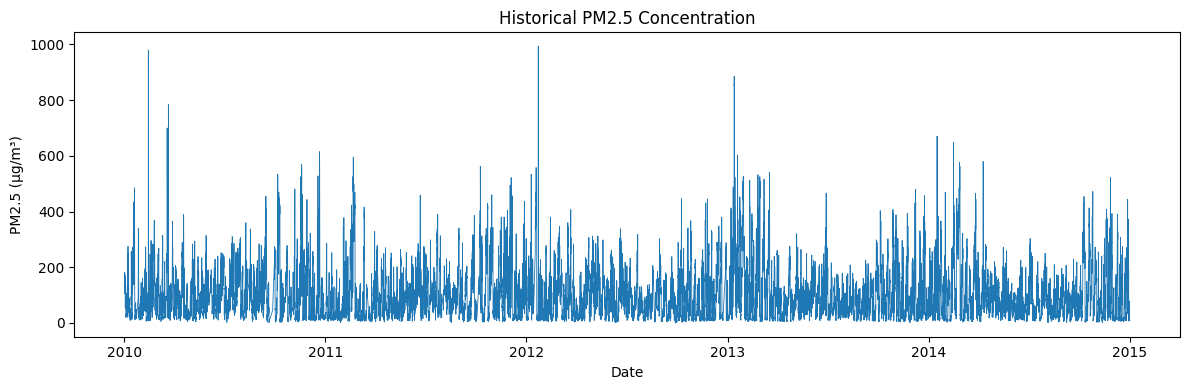

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(df["timestamp"], df["pm2.5"], linewidth=0.6)
plt.title("Historical PM2.5 Concentration")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

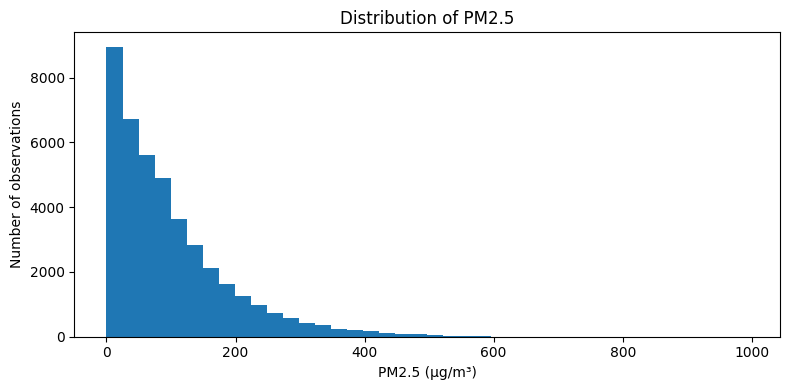

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(df["pm2.5"].dropna(), bins=40)
plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

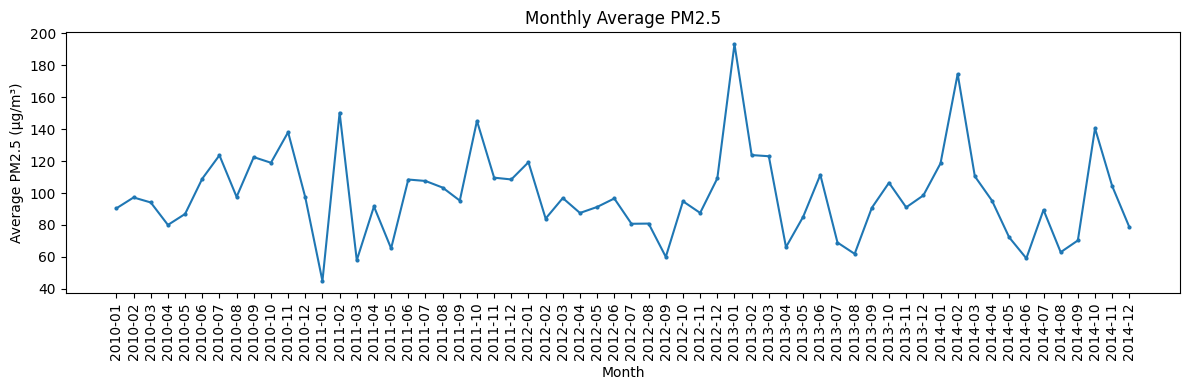

In [ ]:
monthly = df.assign(month_period=df["timestamp"].dt.to_period("M")).groupby("month_period")["pm2.5"].mean()
plt.figure(figsize=(12, 4))
plt.plot(monthly.index.astype(str), monthly.values, marker="o", markersize=2)
plt.title("Monthly Average PM2.5")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

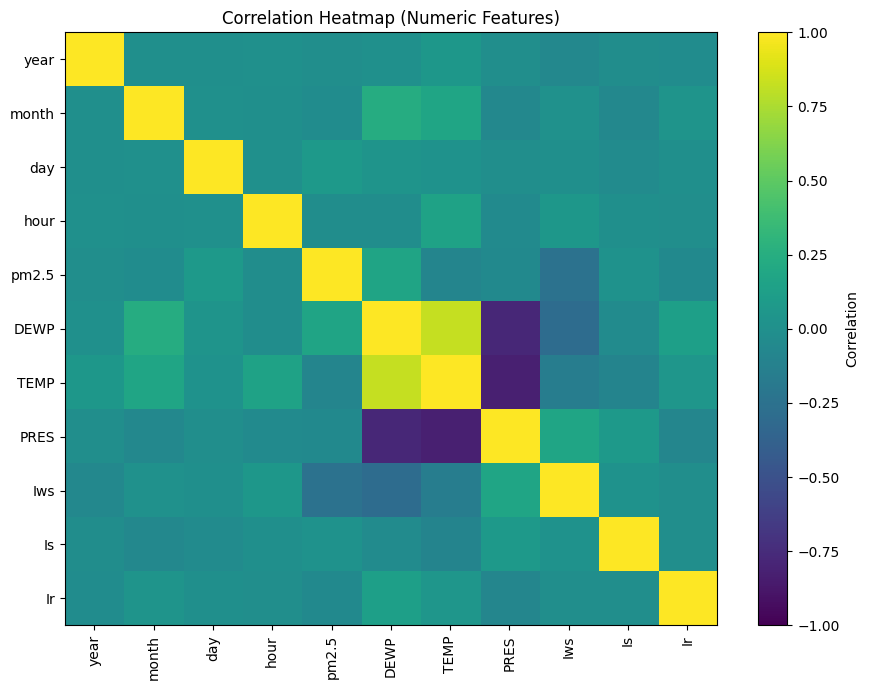

In [ ]:
numeric_for_corr = df.select_dtypes(include=np.number)
corr = numeric_for_corr.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Heatmap (Numeric Features)")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

## 5. Define features and target
We use time-derived features and the dataset's weather/wind measurements. We deliberately do **not** use PM2.5 values from other rows as predictors. The chronological split approximates predicting later observations from earlier-period patterns, although this is not a full multi-step forecasting model.

In [ ]:
# Create time features.
model_df = df.copy()
model_df["day_of_week"] = model_df["timestamp"].dt.dayofweek
model_df["day_of_year"] = model_df["timestamp"].dt.dayofyear

target = "pm2.5"

# Predictors available in this dataset (use only columns that exist).
candidate_features = [
    "year", "month", "day", "hour", "day_of_week", "day_of_year",
    "DEWP", "TEMP", "PRES", "cbwd", "Iws", "Is", "Ir"
]
features = [c for c in candidate_features if c in model_df.columns]

X = model_df[features].copy()
y = model_df[target].copy()

categorical_features = [c for c in X.columns if X[c].dtype == "object"]
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Features:", features)
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
print("Target:", target)

Features: ['year', 'month', 'day', 'hour', 'day_of_week', 'day_of_year', 'DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir']
Categorical features: ['cbwd']
Numeric features: ['year', 'month', 'day', 'hour', 'day_of_week', 'day_of_year', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
Target: pm2.5


## 6. Chronological train/test split
The earliest 80% of observations are used for training and the latest 20% for testing. This is more appropriate for timestamped data than randomly mixing past and future records.

In [ ]:
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()
test_timestamps = model_df["timestamp"].iloc[split_index:].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", model_df["timestamp"].iloc[0], "to", model_df["timestamp"].iloc[split_index - 1])
print("Testing period:", model_df["timestamp"].iloc[split_index], "to", model_df["timestamp"].iloc[-1])

Training rows: 33405
Testing rows: 8352
Training period: 2010-01-02 00:00:00 to 2014-01-14 01:00:00
Testing period: 2014-01-14 02:00:00 to 2014-12-31 23:00:00


## 7. Build and compare regression models
Each model uses a preprocessing pipeline. Missing numeric values are median-imputed and categorical values are most-frequent-imputed and one-hot encoded.

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=18, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

trained_models = {}
results = []

for name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

,Model,MAE,RMSE,R2
0,Random Forest,45.639643,66.552593,0.501704
1,Gradient Boosting,47.630562,66.643940,0.500335
2,Decision Tree,52.503701,78.644994,0.304176
3,Linear Regression,56.718369,81.956036,0.244352


## 8. Select the best model and visualize its predictions
The best model is selected by the lowest test RMSE. Metrics describe performance on this dataset and split only; they do not guarantee performance in another city or period.

In [ ]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Selected model (lowest test RMSE):", best_model_name)
print(f"MAE:  {mean_absolute_error(y_test, best_predictions):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_predictions)):.3f}")
print(f"R²:   {r2_score(y_test, best_predictions):.3f}")

Selected model (lowest test RMSE): Random Forest
MAE:  45.640
RMSE: 66.553
R²:   0.502


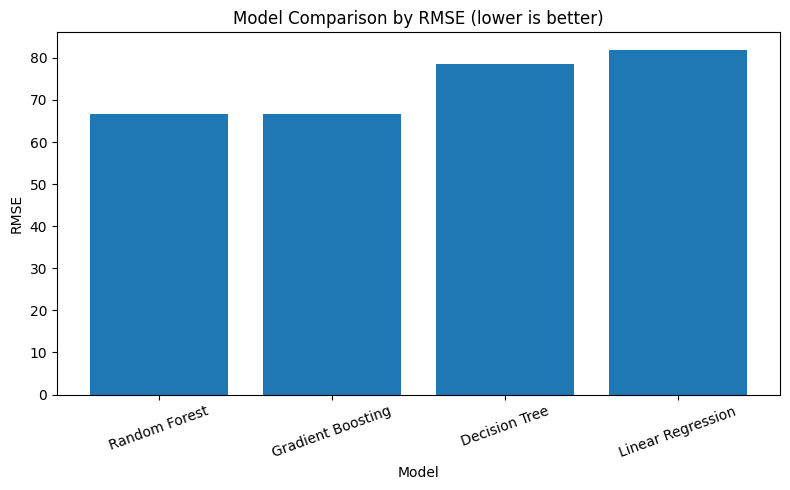

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Model Comparison by RMSE (lower is better)")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

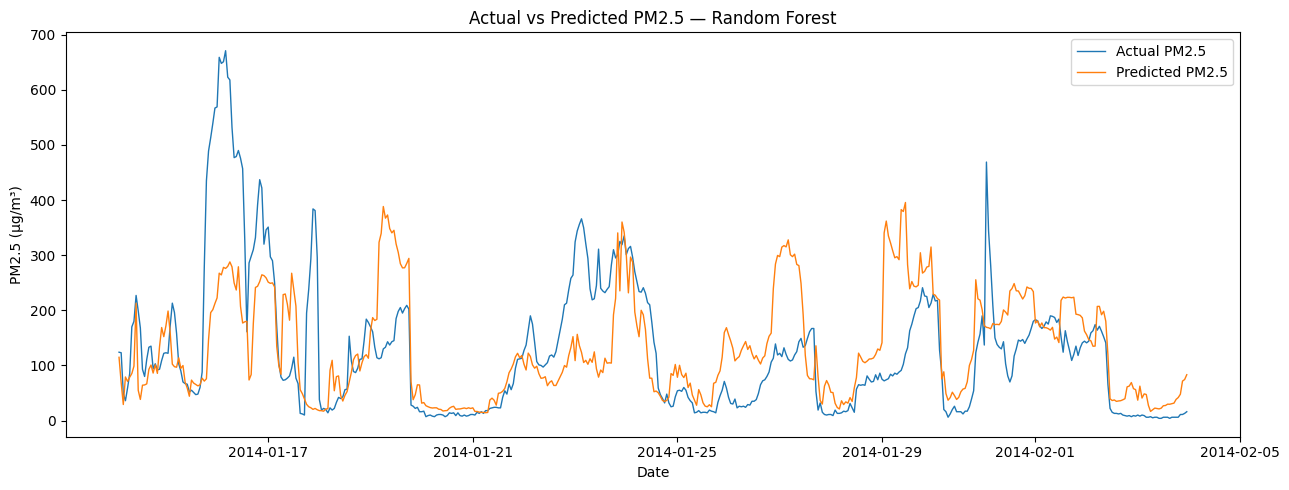

In [ ]:
# Plot a sample of the test period to keep the graph readable.
sample_size = min(500, len(y_test))
plt.figure(figsize=(13, 5))
plt.plot(test_timestamps.iloc[:sample_size], y_test.iloc[:sample_size].values,
         label="Actual PM2.5", linewidth=1)
plt.plot(test_timestamps.iloc[:sample_size], best_predictions[:sample_size],
         label="Predicted PM2.5", linewidth=1)
plt.title(f"Actual vs Predicted PM2.5 — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()

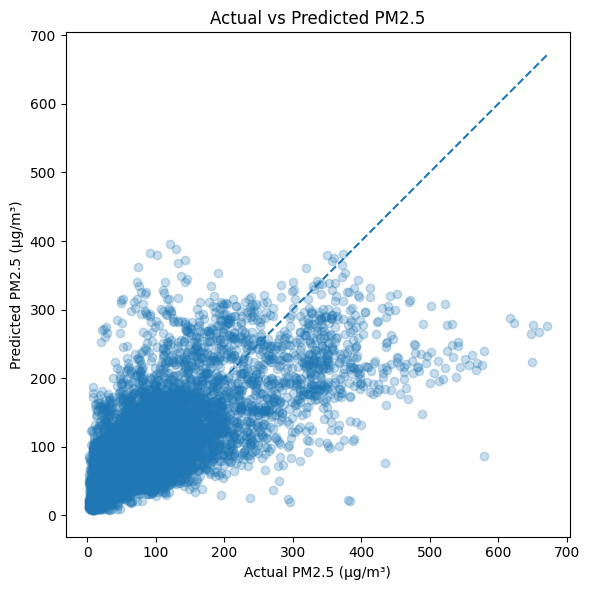

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.25)
min_val = min(float(y_test.min()), float(np.min(best_predictions)))
max_val = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title("Actual vs Predicted PM2.5")
plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

## 9. Inspect a sample of predictions

In [ ]:
prediction_results = pd.DataFrame({
    "timestamp": test_timestamps.values,
    "actual_pm2.5": y_test.values,
    "predicted_pm2.5": best_predictions
})
prediction_results["absolute_error"] = (
    prediction_results["actual_pm2.5"] - prediction_results["predicted_pm2.5"]
).abs()
display(prediction_results.head(15))

,timestamp,actual_pm2.5,predicted_pm2.5,absolute_error
0,2014-01-14 02:00:00,124.0,114.752349,9.247651
1,2014-01-14 03:00:00,123.0,68.652361,54.347639
2,2014-01-14 04:00:00,49.0,29.129389,19.870611
3,2014-01-14 05:00:00,36.0,79.093696,43.093696
4,2014-01-14 06:00:00,59.0,70.941238,11.941238
5,2014-01-14 07:00:00,85.0,78.647641,6.352359
6,2014-01-14 08:00:00,170.0,85.207262,84.792738
7,2014-01-14 09:00:00,180.0,98.770693,81.229307
8,2014-01-14 10:00:00,227.0,212.904841,14.095159
9,2014-01-14 11:00:00,199.0,54.915390,144.084610


## 10. Predict from user-entered measurements
This helper function uses the best trained model. Enter values using the same units and conventions as the dataset. It is a demonstration and should not be used as an official pollution warning.

In [ ]:
def predict_pm25(year, month, day, hour, dew_point, temperature, pressure,
                 wind_direction, wind_speed, snow_hours, rain_hours):
    row = {
        "year": int(year),
        "month": int(month),
        "day": int(day),
        "hour": int(hour),
        "day_of_week": pd.Timestamp(year=int(year), month=int(month), day=int(day)).dayofweek,
        "day_of_year": pd.Timestamp(year=int(year), month=int(month), day=int(day)).dayofyear,
        "DEWP": float(dew_point),
        "TEMP": float(temperature),
        "PRES": float(pressure),
        "cbwd": str(wind_direction),
        "Iws": float(wind_speed),
        "Is": float(snow_hours),
        "Ir": float(rain_hours)
    }
    row_df = pd.DataFrame([{col: row[col] for col in features}])
    prediction = float(best_model.predict(row_df)[0])
    return max(0.0, prediction)

print("Prediction helper ready.")
print("Wind direction options from dataset:", sorted(df["cbwd"].dropna().unique().tolist()) if "cbwd" in df.columns else "Not available")

Prediction helper ready.
Wind direction options from dataset: ['NE', 'NW', 'SE', 'cv']


## 11. Save the trained model and metadata
The model pipeline includes preprocessing, so the saved artifact can accept raw feature columns in the expected format.

In [ ]:
MODEL_PATH = "/content/air_quality_pm25_model.joblib"
METADATA_PATH = "/content/air_quality_model_metadata.txt"

joblib.dump(best_model, MODEL_PATH)

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    f.write("Project: Air Quality Prediction and Pollution Analysis Using Machine Learning\n")
    f.write(f"Dataset: UCI Beijing PM2.5 dataset\n")
    f.write(f"Target: {target}\n")
    f.write(f"Selected model: {best_model_name}\n")
    f.write(f"Features: {features}\n")
    f.write(f"MAE: {mean_absolute_error(y_test, best_predictions):.4f}\n")
    f.write(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_predictions)):.4f}\n")
    f.write(f"R2: {r2_score(y_test, best_predictions):.4f}\n")

print("Saved:", MODEL_PATH)
print("Saved:", METADATA_PATH)

Saved: /content/air_quality_pm25_model.joblib
Saved: /content/air_quality_model_metadata.txt


## 12. Optional: Launch a Gradio demo
Run this cell if you want an interactive interface. If Gradio launch or sharing is restricted in your environment, the trained model and prediction helper above still work in Colab.

In [ ]:
try:
    import gradio as gr

    wind_choices = sorted(df["cbwd"].dropna().astype(str).unique().tolist())
    if not wind_choices:
        wind_choices = ["SE", "NW", "NE", "cv"]

    def gradio_predict(year, month, day, hour, dew_point, temperature, pressure,
                       wind_direction, wind_speed, snow_hours, rain_hours):
        try:
            value = predict_pm25(
                year, month, day, hour, dew_point, temperature, pressure,
                wind_direction, wind_speed, snow_hours, rain_hours
            )
            return f"Predicted PM2.5: {value:.2f} µg/m³\n\nEducational estimate only; not an official air-quality reading or health advisory."
        except Exception as exc:
            return f"Could not generate prediction: {exc}"

    demo = gr.Interface(
        fn=gradio_predict,
        inputs=[
            gr.Number(label="Year", value=2014, precision=0),
            gr.Slider(1, 12, value=6, step=1, label="Month"),
            gr.Slider(1, 31, value=15, step=1, label="Day"),
            gr.Slider(0, 23, value=12, step=1, label="Hour"),
            gr.Number(label="Dew point (DEWP)", value=0),
            gr.Number(label="Temperature (TEMP)", value=20),
            gr.Number(label="Pressure (PRES)", value=1010),
            gr.Dropdown(choices=wind_choices, value=wind_choices[0], label="Wind direction (cbwd)"),
            gr.Number(label="Wind speed (Iws)", value=1),
            gr.Number(label="Snow hours (Is)", value=0),
            gr.Number(label="Rain hours (Ir)", value=0)
        ],
        outputs=gr.Textbox(label="Prediction"),
        title="Air Quality PM2.5 Predictor",
        description="Predicts PM2.5 from weather, wind, and time features using the model trained in this notebook."
    )
    demo.launch(share=True)
except Exception as e:
    print("Gradio demo could not launch in this session:", repr(e))
    print("You can still use predict_pm25(...) directly in a code cell.")

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://63620826e26707f23c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 13. Download model artifacts

In [ ]:
from google.colab import files
files.download(MODEL_PATH)
files.download(METADATA_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Notes for the project report
After running every relevant cell, record the actual values from `results_df` and the selected model's metrics. Do not copy example numbers from elsewhere.

Suggested report figures:
1. Historical PM2.5 time-series plot.
2. PM2.5 distribution histogram.
3. Monthly average PM2.5 trend.
4. Correlation heatmap.
5. Model comparison by RMSE.
6. Actual-versus-predicted graph.

Suggested limitations:
- The dataset covers Beijing, not Mumbai or all cities.
- Historical patterns may not reflect current pollution conditions.
- Missing data and sensor quality can affect predictions.
- This notebook predicts PM2.5 from weather/time/wind features; it is not a validated operational forecasting or public-health warning system.
- Further work could use current local monitoring data, time-series validation, additional locations, and external validation.

**Dataset reference:** UCI Machine Learning Repository, *Beijing PM2.5 Data*. Verify the dataset page and citation details when preparing the final bibliography.